# NLP Basics — the ideas behind COSMOS

This notebook teaches the **natural language processing (NLP)** ideas that power COSMOS, one small step at a time. Every idea is shown first on a few **toy sentences** you can read in full, then on the project's **1,500 demo papers**.

| Part | Idea | Used in COSMOS for |
|---|---|---|
| 1 | Tokens, stop words, stemming | cleaning text before anything else |
| 2 | Bag of words and **TF-IDF** | keyword matching |
| 3 | **Cosine similarity** | comparing any two texts |
| 4 | **LSA embeddings** (SVD) | meaning-based search |
| 5 | Semantic search + **hybrid ranking** | the Search page |
| 6 | **Jaccard** overlap | recommendations |
| 7 | **Co-occurrence** counting | the knowledge graph |
| 8 | Growth rates and **z-scores** | emerging topics |
| 9 | **Grounded** answers with citations | the research assistant |

**How to use it:** run the cells from top to bottom (**Shift + Enter**). Read the text *before* each code cell, and try to predict the output. Every part ends with a short **Try it** exercise.

> **About the data.** The 1,500 papers are **synthetic demo records**: titles start with `[Demo record N]` and the abstracts are templates. They're perfect for learning the mechanics, but don't read anything about real research into the results.

### Setup

You need Python with `numpy`, `scikit-learn` and `matplotlib`. In VS Code, open this notebook and pick a Python kernel (top right). If a package is missing, run this once in a terminal:

```
pip install numpy==1.26.4 scikit-learn==1.5.2 matplotlib==3.9.2 ipykernel
```

In [1]:
!pip install numpy 


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import json
import math
import re
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

# The notebook lives in learning-guide/notebooks/, the data in data/mock/
DATA = Path("../../data/mock")
papers = json.loads((DATA / "papers.json").read_text(encoding="utf-8"))
taxonomy = json.loads((DATA / "taxonomy.json").read_text(encoding="utf-8"))

print(f"{len(papers):,} papers loaded")
p = papers[99]
print("Title:   ", p["title"])
print("Abstract:", p["abstract"])
print("Topics:  ", p["derived"]["topics"], "| synthetic:", p["is_synthetic"])

1,500 papers loaded
Title:    [Demo record 100] Deep Learning applied to computer vision
Abstract: Synthetic placeholder abstract for development. This demo record is tagged with Computer Vision, method "Deep Learning" and technology "Star Trackers". It does not describe real research and will be replaced by the production corpus.
Topics:   ['Computer Vision'] | synthetic: True


---
## Part 1 - From text to clean words

Computers don't see words, only characters. The first job is to cut text into **tokens** (words) and clean them, so that *"Detecting"*, *"detection"* and *"detects"* can be recognised as the same idea.

### 1.1 Tokenization

The simplest tokenizer: lowercase everything and keep runs of letters and digits. Everything else (spaces, punctuation) separates tokens.

In [8]:
TOKEN = re.compile(r"[a-z0-9]+")

def tokenize(text):
    return TOKEN.findall(text.lower())

tokenize("Detecting faults in the spacecraft's star-tracker, quickly!")

['detecting',
 'faults',
 'in',
 'the',
 'spacecraft',
 's',
 'star',
 'tracker',
 'quickly']

Notice `spacecraft's` became `spacecraft` and `s`, and `star-tracker` became two tokens. Tokenizers always make choices like this. There's no perfect one.

### 1.2 Stop words

Words like *the, in, of, and* appear everywhere and carry almost no meaning about the **topic**. We drop them. scikit-learn ships a standard English list.

In [12]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

print(len(ENGLISH_STOP_WORDS), "stop words, e.g.", sorted(ENGLISH_STOP_WORDS)[:8])

def content_words(text):
    return [w for w in tokenize(text) if w not in ENGLISH_STOP_WORDS and len(w) > 1]

content_words("Detecting faults in the spacecraft's star-tracker, quickly!")

318 stop words, e.g. ['a', 'about', 'above', 'across', 'after', 'afterwards', 'again', 'against']


['detecting', 'faults', 'spacecraft', 'star', 'tracker', 'quickly']

### 1.3 Stemming

**Stemming** cuts common endings so related word forms meet: `detecting → detect`, `faults → fault`. COSMOS uses a tiny hand-written stemmer: the longest matching ending is removed, as long as at least 3 letters stay.

It's crude on purpose. It's easy to read, and good enough to join the forms that matter most here.

In [13]:
SUFFIXES = ("ations", "ation", "ions", "ion", "ings", "ing", "ers", "er", "ies", "es", "ed", "s")

def stem(word):
    for suffix in SUFFIXES:
        if word.endswith(suffix) and len(word) - len(suffix) >= 3:
            return word[: -len(suffix)] + ("y" if suffix == "ies" else "")
    return word

for w in ["detecting", "detection", "detects", "faults", "missions", "technologies", "navigation", "series"]:
    print(f"{w:>13} -> {stem(w)}")

    detecting -> detect
    detection -> detect
      detects -> detect
       faults -> fault
     missions -> miss
 technologies -> technology
   navigation -> navig
       series -> sery


Look closely: `navigation → navig` is fine (every form of the word gets the same stem). But `series → sery` is wrong, and `missions → miss` is worse: it now looks exactly like the unrelated word "miss". Real stemmers (Porter, Snowball) and **lemmatizers** (which use a dictionary) are smarter. The trade-off is simplicity against accuracy.

### 1.4 The full cleaning step

COSMOS's `analyze()` puts it all together, and also adds **bigrams** (neighbouring word pairs) such as `fault detect`, so word order isn't completely lost.

In [14]:
def analyze(text):
    words = [stem(w) for w in content_words(text)]
    return words + [f"{a} {b}" for a, b in zip(words, words[1:])]

analyze("AI techniques for detecting spacecraft faults")

['ai',
 'techniqu',
 'detect',
 'spacecraft',
 'fault',
 'ai techniqu',
 'techniqu detect',
 'detect spacecraft',
 'spacecraft fault']


> 1. Run `analyze("Fault detection for spacecraft")`. Which tokens does it share with the question above?
> 2. Find another English word that `stem` gets wrong. Can you fix it with a new rule *without* breaking `detecting`?

---
## Part 2 - Turning text into numbers: bag of words and TF-IDF

To compare texts we need **numbers**. We use five toy sentences (written for this notebook, not real papers):

In [15]:
toy = [
    "optical navigation uses camera images of stars",
    "camera images guide autonomous landing on asteroids",
    "optical sensors help spacecraft navigation near asteroids",
    "electric propulsion uses hall thrusters",
    "hall thrusters erode during long firings",
]
for i, s in enumerate(toy):
    print(i, s)

0 optical navigation uses camera images of stars
1 camera images guide autonomous landing on asteroids
2 optical sensors help spacecraft navigation near asteroids
3 electric propulsion uses hall thrusters
4 hall thrusters erode during long firings


### 2.1 Bag of words

Make a **vocabulary** of every word, then describe each sentence by **how many times** it uses each word. Word order is thrown away, hence "bag".

In [16]:
from sklearn.feature_extraction.text import CountVectorizer

bow = CountVectorizer(analyzer=analyze)
counts = bow.fit_transform(toy)
vocab = bow.get_feature_names_out()

print(len(vocab), "terms in the vocabulary")
single = [i for i, t in enumerate(vocab) if " " not in t]   # show single words only
print("    ", " ".join(f"{vocab[i][:7]:>7}" for i in single))
for n, row in enumerate(counts.toarray()):
    print(f"  {n:>2}", " ".join(f"{row[i]:>7}" for i in single))

43 terms in the vocabulary
     asteroi autonom  camera electri   erode     fir   guide    hall    help    imag    land    long   navig    near optical propuls  sensor spacecr    star  thrust     use
   0       0       0       1       0       0       0       0       0       0       1       0       0       1       0       1       0       0       0       1       0       1
   1       1       1       1       0       0       0       1       0       0       1       1       0       0       0       0       0       0       0       0       0       0
   2       1       0       0       0       0       0       0       0       1       0       0       0       1       1       1       0       1       1       0       0       0
   3       0       0       0       1       0       0       0       1       0       0       0       0       0       0       0       1       0       0       0       1       1
   4       0       0       0       0       1       1       0       1       0       0       0       1       0

Each sentence is now a long row of numbers, mostly zeros. That's called a **sparse vector**.

### 2.2 TF-IDF: important words get big numbers

Raw counts treat every word the same. **TF-IDF** weighs them:

- **TF** (term frequency): how often the word appears **in this text**,
- **IDF** (inverse document frequency): `log((1 + N) / (1 + df)) + 1`, where `df` is how many texts contain the word. **Rare** words get a **high** IDF.

`tfidf = tf × idf`, and then each row is scaled to length 1.

Let's compute IDF by hand and compare it with scikit-learn:

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

N = len(toy)
df = (counts.toarray() > 0).sum(axis=0)          # in how many sentences each term appears
idf_by_hand = np.log((1 + N) / (1 + df)) + 1

tfidf = TfidfVectorizer(analyzer=analyze)
X = tfidf.fit_transform(toy)

for term in ["camera", "navig", "thrust", "land", "erode"]:
    j = list(vocab).index(term)
    print(f"{term:>9}: in {df[j]} sentences  idf by hand {idf_by_hand[j]:.3f}  sklearn {tfidf.idf_[j]:.3f}")

   camera: in 2 sentences  idf by hand 1.693  sklearn 1.693
    navig: in 2 sentences  idf by hand 1.693  sklearn 1.693
   thrust: in 2 sentences  idf by hand 1.693  sklearn 1.693
     land: in 1 sentences  idf by hand 2.099  sklearn 2.099
    erode: in 1 sentences  idf by hand 2.099  sklearn 2.099


The hand calculation matches scikit-learn exactly. Notice the **stems**: "thrusters" became `thrust`, "landing" became `land`. Words in 2 sentences (`camera`, `navig`, `thrust`) have a lower IDF than words in only 1 (`land`, `erode`). In a real corpus, words like "spacecraft" (everywhere) get a low IDF, and distinctive words like "regolith" get a high one.



> Add a sixth toy sentence that uses the word `camera` again, re-run, and watch the IDF of `camera` drop.

---
## Part 3 — Cosine similarity: how close are two texts?

Think of each vector as an **arrow**. Two texts are similar if their arrows point the **same way**. **Cosine similarity** measures this:

$$\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

- `1.0`: same direction (very similar),
- `0.0`: at right angles (nothing in common).

Because TF-IDF rows already have length 1, cosine is just a **dot product**: `X @ X.T` compares every sentence with every other one in one line.

In [9]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

dense = X.toarray()
print("cos(0, 2) by formula:", round(cosine(dense[0], dense[2]), 3))

sims = dense @ dense.T
print("\nAll pairs (rows/cols = sentence 0..4):")
print(sims)

cos(0, 2) by formula: 0.126

All pairs (rows/cols = sentence 0..4):
[[1.    0.211 0.126 0.079 0.   ]
 [0.211 1.    0.061 0.    0.   ]
 [0.126 0.061 1.    0.    0.   ]
 [0.079 0.    0.    1.    0.251]
 [0.    0.    0.    0.251 1.   ]]


Sentences 3 and 4 (both about Hall thrusters) are the most similar pair on the propulsion side, and they score **zero or almost zero** with the navigation sentences. The small 0.079 between sentences 0 and 3 comes only from the shared word "uses", a reminder that common words still leak in.

### 3.1 Keyword search with TF-IDF

To search, embed the **query** the same way and rank the sentences by cosine:

In [10]:
def keyword_search(query, vectorizer, matrix, texts, k=3):
    q = vectorizer.transform([query])
    scores = (matrix @ q.T).toarray().ravel()
    for i in np.argsort(-scores)[:k]:
        print(f"  {scores[i]:.3f}  {texts[i]}")

print("Query: 'camera navigation'")
keyword_search("camera navigation", tfidf, X, toy)

Query: 'camera navigation'
  0.382  optical navigation uses camera images of stars
  0.184  camera images guide autonomous landing on asteroids
  0.165  optical sensors help spacecraft navigation near asteroids


### 3.2 The weakness of keywords

Now search for something that means the same thing **in other words**:

In [11]:
print("Query: 'optical sensors for landing'")
keyword_search("optical sensors for landing", tfidf, X, toy)
print("\nQuery: 'photos for steering'   (no shared words at all)")
keyword_search("photos for steering", tfidf, X, toy)

Query: 'optical sensors for landing'
  0.401  optical sensors help spacecraft navigation near asteroids
  0.169  camera images guide autonomous landing on asteroids
  0.114  optical navigation uses camera images of stars

Query: 'photos for steering'   (no shared words at all)
  0.000  optical navigation uses camera images of stars
  0.000  camera images guide autonomous landing on asteroids
  0.000  optical sensors help spacecraft navigation near asteroids


*"photos for steering"* means much the same as "camera images guide…", yet it scores **0** everywhere. Keyword matching only sees **identical** tokens (after stemming), and nothing tells it that "photos" ≈ "images" or "steering" ≈ "guide". Part 4 starts to fix this with *meaning*.


> Search `"thruster erosion"`. Which sentence wins, and why does `"erode"` vs `"erosion"` matter here?

---
## Part 4 — Embeddings: from words to meaning (LSA)

**LSA (Latent Semantic Analysis)** squeezes the long TF-IDF vectors into a few numbers per text using **SVD** (singular value decomposition, from linear algebra).

The key effect: words that **appear together** in many texts end up pointing in **similar directions**. In our toy sentences "camera" appears with "navigation" and "images", and "optical" appears with "navigation" too. After LSA, a text about cameras and a text about optical sensors can be close **even with few shared words**.

These short vectors are called **embeddings**.

In [12]:
from sklearn.decomposition import TruncatedSVD

def unit(m):
    n = np.linalg.norm(m, axis=1, keepdims=True)
    return m / np.where(n == 0, 1, n)

svd_toy = TruncatedSVD(n_components=2, random_state=0)
E = unit(svd_toy.fit_transform(X))          # 5 sentences -> 2 numbers each
print("Toy embeddings (2 numbers per sentence):")
for e, s in zip(E, toy):
    print(f"  [{e[0]:+.2f} {e[1]:+.2f}]  {s}")

print("\nSimilarity of sentence 0 to the others:")
print("  TF-IDF:", (dense @ dense[0]).round(2))
print("  LSA:   ", (E @ E[0]).round(2))

Toy embeddings (2 numbers per sentence):
  [+0.87 -0.50]  optical navigation uses camera images of stars
  [+0.77 -0.64]  camera images guide autonomous landing on asteroids
  [+0.76 -0.65]  optical sensors help spacecraft navigation near asteroids
  [+0.66 +0.75]  electric propulsion uses hall thrusters
  [+0.55 +0.84]  hall thrusters erode during long firings

Similarity of sentence 0 to the others:
  TF-IDF: [1.   0.21 0.13 0.08 0.  ]
  LSA:    [1.   0.99 0.98 0.2  0.06]


With TF-IDF, sentence 0 (optical navigation) and sentence 1 (camera images guide landing) share only `camera` and `image`. In the 2-D LSA space the three navigation sentences crowd together, and the two propulsion sentences sit far away. LSA found two **themes** — navigation and propulsion — without being told.

### 4.1 LSA on the real demo corpus

COSMOS embeds each paper's title, abstract and tags into **128** numbers. Let's do the same, then draw the papers in 2-D using the first two LSA dimensions, and see what LSA picked up on its own.

In [13]:
def paper_text(p):
    d = p["derived"]
    return " ".join([p["title"], p["abstract"], *d["topics"], *d["methods"], *d["technologies"], *d["missions"]])

texts = [paper_text(p) for p in papers]
corpus_tfidf = TfidfVectorizer(analyzer=analyze, sublinear_tf=True)
S = corpus_tfidf.fit_transform(texts)
svd = TruncatedSVD(n_components=128, random_state=0)
V = unit(svd.fit_transform(S))

print("TF-IDF matrix:", S.shape, f"({S.nnz / (S.shape[0] * S.shape[1]):.2%} non-zero)")
print("LSA embeddings:", V.shape)

TF-IDF matrix: (1500, 5571) (1.03% non-zero)
LSA embeddings: (1500, 128)


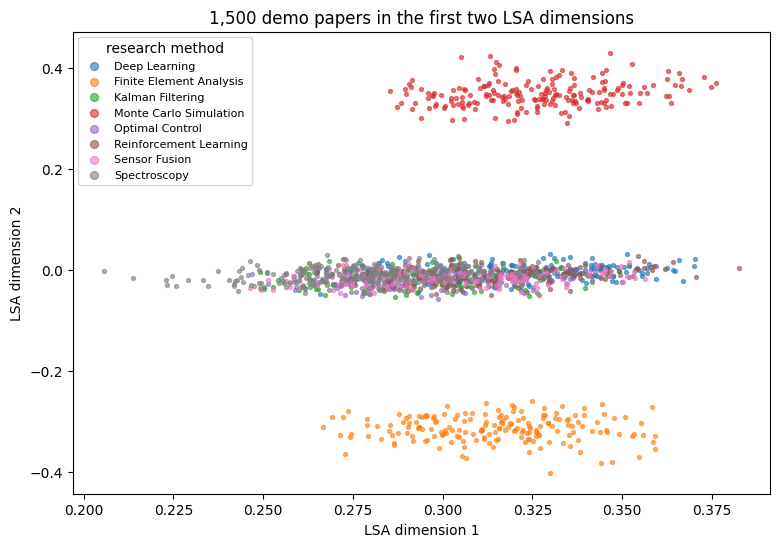

In [14]:
xy = TruncatedSVD(n_components=2, random_state=0).fit_transform(S)
method = [p["derived"]["methods"][0] for p in papers]

plt.figure(figsize=(9, 6))
for name in sorted(set(method)):
    idx = [i for i, m in enumerate(method) if m == name]
    plt.scatter(xy[idx, 0], xy[idx, 1], s=8, alpha=0.6, label=name)
plt.legend(fontsize=8, markerscale=2, loc="best", title="research method")
plt.title("1,500 demo papers in the first two LSA dimensions")
plt.xlabel("LSA dimension 1"); plt.ylabel("LSA dimension 2")
plt.show()

**Surprise: three bands, and they are research methods.** The top band is entirely *Monte Carlo Simulation* papers and the bottom band entirely *Finite Element Analysis*.

Why? The demo template repeats the method name in the title ("Monte Carlo Simulation applied to…"), in the abstract and in the tags. So the method words are the strongest pattern in this text, and LSA's first dimensions capture the **strongest patterns**, whatever they are.

That's an important lesson: **LSA finds the patterns that are really in your text, not the ones you hoped for.** With real abstracts the strongest patterns are usually subject matter.

So are domains captured at all? Two dimensions throw most of the information away. Let's measure in all 128: are papers from the **same domain** closer to each other than to papers from **other** domains?

In [15]:
domain_of = {t: d["name"] for d in taxonomy["domains"] for t in d["topics"]}
labels = np.array([domain_of[p["derived"]["topics"][0]] for p in papers])

sims_all = V @ V.T                                   # 1,500 x 1,500 cosine similarities
same = labels[:, None] == labels[None, :]
np.fill_diagonal(same, False)                        # ignore each paper vs itself
other = ~same & ~np.eye(len(papers), dtype=bool)

print(f"average similarity, same domain:      {sims_all[same].mean():.3f}")
print(f"average similarity, different domain: {sims_all[other].mean():.3f}")

average similarity, same domain:      0.260


average similarity, different domain: 0.111


Papers in the same domain are, on average, **more than twice as similar** as papers from different domains. The domain structure **is** in the embeddings. It just doesn't show up in the first two dimensions, which the template's method words dominate.

> 1. Change `n_components=2` to `3` in the toy cell. Does sentence 1 get closer to sentence 0? What do you think the third dimension captured?
> 2. Re-draw the scatter coloured by **domain** (use `labels` instead of `method`). Can you see the domains in 2-D? Why not?

---
## Part 5 — Semantic search and hybrid ranking

Now the Search page itself. Steps:

1. Embed the question into the **same** 128-dimension space.
2. **Interpret** it: which taxonomy topics is it about? (embedding similarity + shared stems)
3. Score every paper on **four signals** and mix them:

| Signal | Meaning | Weight |
|---|---|---|
| semantic | LSA cosine with the question | 0.5 |
| keyword | TF-IDF cosine (scaled so the best = 1) | 0.2 |
| topic | share of interpreted topics the paper is tagged with | 0.2 |
| entity | question words matching the paper's methods / technologies / missions | 0.1 |

In [16]:
QUESTION_WORDS = {"what", "how", "which", "used", "using", "techniques", "research", "researchers",
                  "working", "being", "make", "becoming", "space", "spacecraft"}
WEIGHTS = {"semantic": 0.5, "keyword": 0.2, "topic": 0.2, "entity": 0.1}
topics = [t for d in taxonomy["domains"] for t in d["topics"]]

def embed(texts_):
    return unit(svd.transform(corpus_tfidf.transform(texts_)))

def key_terms(text):
    return {stem(w) for w in tokenize(text) if len(w) > 2 and w not in ENGLISH_STOP_WORDS and w not in QUESTION_WORDS}

topic_vectors = embed(topics)

def interpret(question, qv, k=4):
    q = key_terms(question)
    scored = []
    for topic, sim in zip(topics, topic_vectors @ qv):
        t = key_terms(topic)
        scored.append((0.6 * sim + 0.4 * (len(t & q) / len(t) if t else 0), topic))
    scored.sort(reverse=True)
    best = scored[0][0]
    return [t for s, t in scored[:k] if s >= 0.3 and s >= 0.6 * best]

question = "AI techniques for detecting spacecraft faults"
qv = embed([question])[0]
print("Key terms:     ", key_terms(question))
print("Interpreted as:", interpret(question, qv))

Key terms:      {'detect', 'fault'}
Interpreted as: ['Fault Detection']


In [17]:
entity_terms = [key_terms(" ".join(p["derived"]["methods"] + p["derived"]["technologies"] + p["derived"]["missions"])) for p in papers]

def search(question, k=5):
    qv = embed([question])[0]
    interp = interpret(question, qv)
    q = key_terms(question)
    semantic = np.clip(V @ qv, 0, 1)
    keyword = (S @ corpus_tfidf.transform([question]).T).toarray().ravel()
    keyword = keyword / (keyword.max() or 1)
    rows = []
    for i, p in enumerate(papers):
        on = [t for t in interp if t in p["derived"]["topics"]]
        parts = {
            "semantic": semantic[i],
            "keyword": keyword[i],
            "topic": len(on) / len(interp) if interp else 0,
            "entity": min(1, len(q & entity_terms[i]) / len(q)) if q else 0,
        }
        overall = 100 * sum(WEIGHTS[n] * v for n, v in parts.items())
        rows.append((overall, i, parts))
    rows.sort(key=lambda r: -r[0])
    print(f"Q: {question}\nInterpreted as: {interp}\n")
    print(f"{'overall':>7} {'sem':>4} {'kw':>4} {'top':>4} {'ent':>4}  paper")
    for overall, i, parts in rows[:k]:
        sem, kw, top, ent = (round(100 * parts[n]) for n in ("semantic", "keyword", "topic", "entity"))
        print(f"{overall:7.0f} {sem:4} {kw:4} {top:4} {ent:4}  {papers[i]['title'][:60]}")

search("AI techniques for detecting spacecraft faults")

Q: AI techniques for detecting spacecraft faults
Interpreted as: ['Fault Detection']

overall  sem   kw  top  ent  paper
     70   63   92  100    0  [Demo record 1044] Optimal Control applied to fault detectio
     68   60   90  100    0  [Demo record 113] Spectroscopy applied to fault detection
     68   60   90  100    0  [Demo record 1477] Deep Learning applied to fault detection
     66   57   87  100    0  [Demo record 797] Sensor Fusion applied to fault detection
     59   39  100  100    0  [Demo record 1465] Optimal Control applied to autonomous spa


Every result shows **why** it ranked where it did. That's the spec's rule: *never show a meaningless score alone.*

> **✏️ Try it (Part 5)**
> 1. Search `"optical navigation for small bodies"` and `"how do thrusters wear out"`.
> 2. Set the keyword weight to `0.6` and semantic to `0.1` (keep the total at 1.0). How do the results change?

---
## Part 6 — Recommendations: Jaccard overlap and "kinds" of related

To recommend papers we compare **sets** (topics, methods…). **Jaccard similarity** = shared items ÷ all items:

$$J(A,B) = \frac{|A \cap B|}{|A \cup B|}$$

In [18]:
def jaccard(a, b):
    return len(a & b) / len(a | b) if a or b else 0.0

print(jaccard({"Computer Vision", "Spacecraft Navigation"}, {"Computer Vision"}))          # 1 shared / 2 total
print(jaccard({"Computer Vision"}, {"Electric Propulsion"}))                               # nothing shared

0.5
0.0


COSMOS sorts other papers into three **kinds**, so recommendations aren't all near-copies:

- **very similar**: shares at least half the topics, ranked mostly by semantic similarity,
- **related**: shares a topic or an **entity** (a technology or mission) but uses a **different method**: another approach,
- **adjacent**: shares no topic, but sits in a *neighbouring* field (see Part 7).

In [19]:
def entities(p):
    d = p["derived"]
    return set(d["technologies"]) | set(d["missions"])

def kinds_for(i, k=3):
    p = papers[i]
    sims = V @ V[i]
    T, M, E = set(p["derived"]["topics"]), set(p["derived"]["methods"]), entities(p)
    very, related = [], []
    for j, c in enumerate(papers):
        if j == i:
            continue
        ct, cm, ce = set(c["derived"]["topics"]), set(c["derived"]["methods"]), entities(c)
        if len(T & ct) >= max(1, len(T) / 2):                       # shares most topics
            very.append((0.6 * sims[j] + 0.25 * jaccard(T, ct), j))
        elif (T & ct or E & ce) and not M & cm:                      # shares a topic or entity, other method
            related.append((0.35 * sims[j] + 0.3 * jaccard(T, ct) + 0.3 * jaccard(E, ce), j))
    print("Paper:", p["title"])
    print("  topics:", sorted(T), "| methods:", sorted(M), "| entities:", sorted(E))
    for name, items in (("Very similar", very), ("Related (shared topic or entity, other method)", related)):
        print(f"\n{name}:")
        for s, j in sorted(items, reverse=True)[:k]:
            c = papers[j]["derived"]
            print(f"  {s:.2f}  {papers[j]['title'][:50]}  methods={c['methods']} entities={c['technologies'] + c['missions']}")

kinds_for(99)

Paper: [Demo record 100] Deep Learning applied to computer vision
  topics: ['Computer Vision'] | methods: ['Deep Learning'] | entities: ['Deep-Space Probe (demo)', 'Star Trackers']

Very similar:
  0.68  [Demo record 503] Optimal Control applied to compu  methods=['Optimal Control'] entities=['Star Trackers']
  0.66  [Demo record 789] Finite Element Analysis applied   methods=['Finite Element Analysis'] entities=['Star Trackers']
  0.61  [Demo record 958] Reinforcement Learning applied t  methods=['Reinforcement Learning'] entities=['Laser Communication', 'Asteroid Sample Return (demo)']

Related (shared topic or entity, other method):
  0.42  [Demo record 1107] Reinforcement Learning applied   methods=['Reinforcement Learning'] entities=['Star Trackers', 'Deep-Space Probe (demo)']
  0.42  [Demo record 1236] Reinforcement Learning applied   methods=['Reinforcement Learning'] entities=['Star Trackers', 'Deep-Space Probe (demo)']
  0.42  [Demo record 1354] Kalman Filtering applied to sp

> **✏️ Try it (Part 6)**
> Pick another paper index (try `0`, `500`, `1200`). Do the "related" papers really use a different method every time?

---
## Part 7 — Co-occurrence: the knowledge graph

A **knowledge graph** is nodes (topics, countries, methods…) joined by edges. In COSMOS two nodes are joined when **the same papers mention both**, and the edge **weight** is how many papers that is. This is pure counting. No model, no guessing.

In [20]:
pairs = Counter()
for p in papers:
    ts = sorted(set(p["derived"]["topics"]))
    for a_i, a in enumerate(ts):
        for b in ts[a_i + 1:]:
            pairs[(a, b)] += 1

print("Strongest topic pairs (edge weight = shared papers):")
for (a, b), n in pairs.most_common(6):
    print(f"  {n:3}  {a}  <->  {b}")

Strongest topic pairs (edge weight = shared papers):
   23  Radiation Effects  <->  Space Weather
   23  Life-Support Systems  <->  Space Medicine
   22  Radiation Effects  <->  Solar Physics
   20  Life Detection  <->  Planetary Atmospheres
   18  Advanced Propulsion Concepts  <->  Rocket Propulsion
   18  Deep-Space Missions  <->  Mars Exploration


In [21]:
def neighbours(entity_topic, per_kind=4):
    mine = [p for p in papers if entity_topic in p["derived"]["topics"]]
    countries = Counter(p["country"] for p in mine if p["country"])
    methods = Counter(m for p in mine for m in p["derived"]["methods"])
    other_topics = Counter(t for p in mine for t in p["derived"]["topics"] if t != entity_topic)
    print(f"{entity_topic}: {len(mine)} papers")
    for name, c in (("topics", other_topics), ("countries", countries), ("methods", methods)):
        print(f"  top {name:<9}", c.most_common(per_kind))

neighbours("Computer Vision")

Computer Vision: 65 papers
  top topics    [('Fault Detection', 12), ('Machine Learning', 11), ('Mission Planning', 7), ('Onboard AI', 5)]
  top countries [('United States', 18), ('China', 14), ('South Korea', 6), ('India', 5)]
  top methods   [('Reinforcement Learning', 12), ('Monte Carlo Simulation', 12), ('Kalman Filtering', 8), ('Deep Learning', 7)]


Keeping only the strongest few per kind (`per_kind=4`) is what stops the map from becoming an unreadable "hairball".

> **✏️ Try it (Part 7)**
> Count which **country pairs** never appear together. (They can't: a paper has one country here. Why does that mean countries never link directly to each other in the graph?)

---
## Part 8 — Trends: growth that means something

Is a topic **emerging**? Raw counts mislead, because the whole corpus may grow every year. So we compare a topic's growth **to the corpus's growth**, and we use a **z-score** to ask whether the change is bigger than chance.

```
recent window = last 3 years, baseline = everything before
growth ×  = (topic recent rate ÷ topic baseline rate) ÷ (corpus recent rate ÷ corpus baseline rate)
expected  = baseline rate × 3 years × corpus growth
z         = (recent − expected) ÷ √expected      (Poisson approximation for counts)
```

In [22]:
years = list(range(min(p["publication_year"] for p in papers), max(p["publication_year"] for p in papers) + 1))

def per_year(ps):
    c = Counter(p["publication_year"] for p in ps)
    return [c.get(y, 0) for y in years]

totals = per_year(papers)
n_base, W = len(years) - 3, 3
corpus_growth = (sum(totals[n_base:]) / W) / (sum(totals[:n_base]) / n_base)
print("Corpus papers per year:", totals)
print(f"Corpus growth: x{corpus_growth:.2f}")

def trend(topic):
    counts = per_year([p for p in papers if topic in p["derived"]["topics"]])
    base, recent = sum(counts[:n_base]), sum(counts[n_base:])
    base_rate = base / n_base
    growth_raw = (recent / W) / base_rate
    growth = growth_raw / corpus_growth
    expected = base_rate * W * corpus_growth
    z = (recent - expected) / math.sqrt(max(expected, 1))
    return counts, growth_raw, growth, z

for t in ["Onboard AI", "Rocket Propulsion", "Asteroid Exploration"]:
    counts, raw, g, z = trend(t)
    print(f"{t:<22} raw x{raw:.2f}  relative x{g:.2f}  z={z:+.1f}  {counts}")

Corpus papers per year: [117, 105, 103, 116, 108, 116, 120, 116, 138, 161, 147, 153]
Corpus growth: x1.33
Onboard AI             raw x3.32  relative x2.49  z=+6.1  [0, 2, 5, 4, 7, 4, 2, 7, 7, 9, 17, 16]
Rocket Propulsion      raw x1.00  relative x0.75  z=-1.2  [6, 6, 6, 7, 7, 7, 3, 5, 4, 8, 2, 7]
Asteroid Exploration   raw x0.44  relative x0.33  z=-3.5  [4, 9, 5, 5, 6, 9, 7, 4, 12, 6, 1, 2]


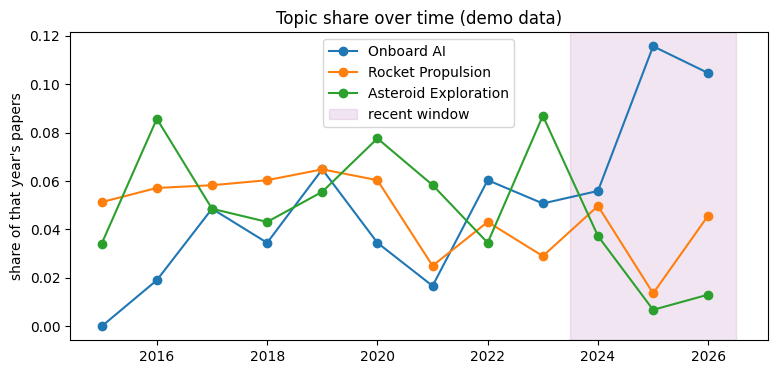

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
for t in ["Onboard AI", "Rocket Propulsion", "Asteroid Exploration"]:
    counts = per_year([p for p in papers if t in p["derived"]["topics"]])
    share = [c / max(1, n) for c, n in zip(counts, totals)]
    ax.plot(years, share, marker="o", label=t)
ax.axvspan(years[n_base] - 0.5, years[-1] + 0.5, alpha=0.1, color="purple", label="recent window")
ax.set_ylabel("share of that year's papers"); ax.set_title("Topic share over time (demo data)")
ax.legend(); plt.show()

Compare the **raw** and **relative** growth columns. Rocket Propulsion publishes just as much as before (raw ×1.00), but because the corpus grew ×1.33 its **share** fell (relative ×0.75). And the z-score keeps tiny topics from shouting: going from 1 to 3 papers is a big ratio but a small z.

The demo generator deliberately makes "Onboard AI" more common in recent years, so it should come out on top. The wording rule still applies: say *"emerging topic signal in this corpus"*, never *"this is the future"*.

> **✏️ Try it (Part 8)**
> Change the window `W` (and `n_base`) to 5 years. Which topics' z-scores change most?

---
## Part 9 — Grounded answers with citations (RAG)

**RAG (retrieval-augmented generation)** = find relevant texts first, then answer **only** from them. The COSMOS assistant:

1. **retrieves** sources (here: our LSA search),
2. **gates**: if the best source is weak, it says *"not enough evidence"*,
3. **generates**: here *extractively*, by quoting the source sentences that best match the question, each with its `[n]`,
4. **verifies**: every `[n]` must point at a real source.

Quoting can't invent anything, which makes it a safe baseline. An LLM can write nicer prose, but it must pass the same checks.

In [24]:
INSUFFICIENT = "The corpus does not contain enough evidence to answer this."

def sentences(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if len(s.strip()) > 20]

def answer(question, k=3, min_top=0.35):
    sims = V @ embed([question])[0]
    top = np.argsort(-sims)[:k]
    if sims[top[0]] < min_top:                                   # the evidence gate
        return INSUFFICIENT, []
    q = set(analyze(question))
    scored = []
    for n, i in enumerate(top, start=1):
        for sent in sentences(papers[i]["abstract"]):
            overlap = len(q & set(analyze(sent)))
            if overlap:
                scored.append((overlap, -n, sent, n))
    if not scored:
        return INSUFFICIENT, []
    picked, seen = [], set()
    for _, _, sent, n in sorted(scored, reverse=True):
        if sent not in seen:
            seen.add(sent); picked.append(f"{sent.rstrip('.')} [{n}].")
        if len(picked) == 2:
            break
    return " ".join(picked), [papers[i]["title"] for i in top]

text, sources = answer("What techniques are used to detect spacecraft faults?")
print(text, "\n")
for n, title in enumerate(sources, start=1):
    print(f"[{n}] {title}")

This demo record is tagged with Fault Detection and Spacecraft Navigation, method "Optimal Control" and technology "Laser Communication" [1]. This demo record is tagged with Fault Detection and Spacecraft Systems Engineering, method "Deep Learning" and technology "Laser Communication" [2]. 

[1] [Demo record 1044] Optimal Control applied to fault detection
[2] [Demo record 1477] Deep Learning applied to fault detection
[3] [Demo record 113] Spectroscopy applied to fault detection


In [25]:
CITE = re.compile(r"\[(\d+)\]")

def verify(answer_text, n_sources):
    valid = lambda n: 1 <= int(n) <= n_sources
    bad = sorted({int(n) for n in CITE.findall(answer_text) if not valid(n)})
    clean = CITE.sub(lambda m: m.group(0) if valid(m.group(1)) else "", answer_text)
    clean = re.sub(r"\s+([.,;])", r"\1", clean)   # tidy the space left behind
    return clean, bad

print(verify("Cameras are used [1]. Lasers are used [7].", n_sources=3))
print(answer("zzzz qqqq")[0])

('Cameras are used [1]. Lasers are used.', [7])
The corpus does not contain enough evidence to answer this.


The fake citation `[7]` was removed and reported, and the nonsense question got the honest *"not enough evidence"* reply instead of a made-up answer.

> **✏️ Try it (Part 9)**
> 1. Raise `min_top` to `0.6`. Which questions now get "not enough evidence"?
> 2. Ask a question about a topic not in the corpus, e.g. *"How do bees make honey?"*. What happens, and why is that the right behaviour?

---
## Summary — where each idea lives in COSMOS

| Idea | Notebook part | Finished COSMOS file | Course lesson |
|---|---|---|---|
| Tokenize, stop words, stem, bigrams | 1 | `backend/app/search/text.py` | 12 |
| TF-IDF | 2 | `backend/app/search/engine.py` | 12 |
| Cosine similarity | 3 | `backend/app/search/index.py` | 12 |
| LSA embeddings (SVD) | 4 | `backend/app/search/embedders.py` | 12 |
| Topic interpretation + hybrid ranking | 5 | `backend/app/search/engine.py` | 12 |
| Jaccard + recommendation kinds | 6 | `backend/app/recommend.py` | 13 |
| Co-occurrence graph | 7 | `backend/app/graph.py` | 14 |
| Corpus-relative growth, z-scores | 8 | `backend/app/trends.py` | 15 |
| RAG: retrieve, gate, generate, verify | 9 | `backend/app/rag/` | 17 |

### Where to go next

- **Better stemming:** try `nltk`'s Porter stemmer or `spaCy` lemmatization in Part 1.
- **Neural embeddings:** replace LSA with `sentence-transformers` (`all-MiniLM-L6-v2`) in Part 4. It knows "imaging" ≈ "camera" without needing co-occurrence in *your* corpus.
- **Evaluation:** write 10 questions with the papers you'd expect, and measure how many appear in the top 5 (*recall@5*). That's how you'd compare LSA with neural embeddings fairly.
- **Real data:** everything here runs unchanged on the real corpus once it's imported (course Lesson 18). The templated demo abstracts are why some results look repetitive.